# Chapter 23: The EM Algorithm and Generalised Linear Models

The computational applications of this chapter of *Theory of Statistics*. The code is generated automatically from the book's `code/ch23/` files; see the book for the explanations and proofs.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/izupress/statistical-theory/blob/main/notebooks/ch_23.ipynb)

$$
\newcommand{\R}{\mathbb{R}}\newcommand{\N}{\mathbb{N}}\newcommand{\E}{\mathbb{E}}
\newcommand{\P}{\mathbb{P}}\newcommand{\F}{\mathcal{F}}\newcommand{\I}{\mathbb{I}}
\newcommand{\Var}{\operatorname{Var}}\newcommand{\Cov}{\operatorname{Cov}}
\newcommand{\Corr}{\operatorname{Corr}}\newcommand{\MSE}{\operatorname{MSE}}
\newcommand{\Bias}{\operatorname{Bias}}\newcommand{\Normal}{\mathcal{N}}
\newcommand{\iid}{\overset{\text{i.i.d.}}{\sim}}\newcommand{\pto}{\xrightarrow{P}}
\newcommand{\dto}{\xrightarrow{d}}\newcommand{\X}{\mathbf{X}}\newcommand{\x}{\mathbf{x}}
$$

In [1]:
# Setup: numpy, scipy and matplotlib are preinstalled on Colab. Locally:
#   pip install -r code/requirements.txt
# Figure files (PDF) saved by the code are written to the _figures/ folder; the figures are
# also shown inside the notebook.
import os
os.makedirs("_figures", exist_ok=True)
os.chdir("_figures")
%matplotlib inline

## EM: Linkage Data and a Normal Mixture

*Source file:* `code/ch23/c23_1_em_mixture_and_linkage.py`

Linkage data: EM iterations = [0.608247 0.624321 0.626489 0.626777 0.626816 0.626821]
Direct MLE = 0.626821 | successive error ratios = [0.1346 0.133  0.1328 0.1328 0.1328]
Mixture: 121 iterations | log-likelihood -1324.52 -> -859.4867
Smallest increase = 9.89e-11 (non-negative: monotonicity)
Estimates: w = 0.318 (0.35), mu = (0.083, 3.984) (0, 4), sigma = (1.473, 0.903) (1.5, 1)


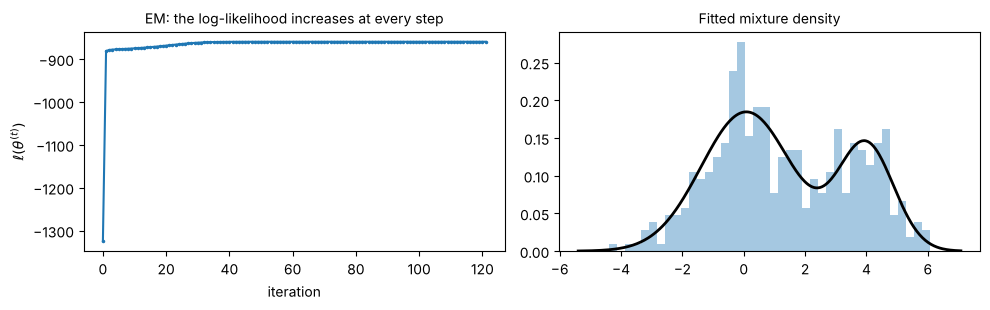

In [2]:
import numpy as np
from scipy import stats, optimize
import matplotlib.pyplot as plt

# (a) The Dempster--Laird--Rubin genetic linkage example: y = (125, 18, 20, 34),
# cell probabilities (1/2 + t/4, (1-t)/4, (1-t)/4, t/4). The first cell is split into (1/2) and (t/4).
y1, y2, y3, y4 = 125, 18, 20, 34
t, trace = 0.5, []
for _ in range(10):
    x2 = y1 * (t / 4) / (0.5 + t / 4)            # E-step: expected count falling in the t/4 part of the first cell
    t = (x2 + y4) / (x2 + y2 + y3 + y4)          # M-step: complete-data MLE of the binomial proportion
    trace.append(t)
ll = lambda t: y1*np.log(0.5 + t/4) + (y2 + y3)*np.log((1 - t)/4) + y4*np.log(t/4)
t_hat = optimize.brentq(lambda t: y1/(2 + t) - (y2 + y3)/(1 - t) + y4/t, 0.01, 0.99)
err = np.abs(np.array(trace) - t_hat)
print(f"Linkage data: EM iterations = {np.round(trace[:6], 6)}")
print(f"Direct MLE = {t_hat:.6f} | successive error ratios = {np.round(err[1:6] / err[:5], 4)}")

# (b) Two-component normal mixture
rng = np.random.default_rng(42)
n = 400
z = rng.random(n) < 0.35
x = np.where(z, rng.normal(4.0, 1.0, n), rng.normal(0.0, 1.5, n))
w, m1, m2, s1, s2 = 0.5, -1.0, 1.0, 1.0, 1.0            # deliberately poor start
def loglik(w, m1, m2, s1, s2):
    return np.log((1 - w) * stats.norm.pdf(x, m1, s1) + w * stats.norm.pdf(x, m2, s2)).sum()
hist = [loglik(w, m1, m2, s1, s2)]
for it in range(200):
    a = w * stats.norm.pdf(x, m2, s2); b = (1 - w) * stats.norm.pdf(x, m1, s1)
    g = a / (a + b)                                        # E-step: posterior membership probabilities
    w = g.mean()                                           # M-step: weighted MLEs
    m1, m2 = np.sum((1 - g) * x) / np.sum(1 - g), np.sum(g * x) / np.sum(g)
    s1 = np.sqrt(np.sum((1 - g) * (x - m1)**2) / np.sum(1 - g))
    s2 = np.sqrt(np.sum(g * (x - m2)**2) / np.sum(g))
    hist.append(loglik(w, m1, m2, s1, s2))
    if hist[-1] - hist[-2] < 1e-10: break
diffs = np.diff(hist)
print(f"Mixture: {it + 1} iterations | log-likelihood {hist[0]:.2f} -> {hist[-1]:.4f}")
print(f"Smallest increase = {diffs.min():.2e} (non-negative: monotonicity)")
print(f"Estimates: w = {w:.3f} (0.35), mu = ({m1:.3f}, {m2:.3f}) (0, 4), sigma = ({s1:.3f}, {s2:.3f}) (1.5, 1)")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(hist, ".-", ms=3); ax[0].set_xlabel("iteration"); ax[0].set_ylabel(r"$\ell(\theta^{(t)})$")
ax[0].set_title("EM: the log-likelihood increases at every step", fontsize=10)
grd = np.linspace(x.min() - 1, x.max() + 1, 400)
ax[1].hist(x, bins=40, density=True, alpha=0.4)
ax[1].plot(grd, (1 - w) * stats.norm.pdf(grd, m1, s1) + w * stats.norm.pdf(grd, m2, s2), "k", lw=2)
ax[1].set_title("Fitted mixture density", fontsize=10)
fig.tight_layout(); fig.savefig("em_karisim.pdf")

## Logistic Regression: IRLS, Wald Intervals and Complete Separation

*Source file:* `code/ch23/c23_2_logistic_irls.py`

In [3]:
import numpy as np
from scipy import optimize, special

rng = np.random.default_rng(42)

def irls(X, y, tol=1e-10, maxit=50):
    beta = np.zeros(X.shape[1])
    for it in range(maxit):
        eta = X @ beta; mu = special.expit(eta); W = mu * (1 - mu)
        z = eta + (y - mu) / W                            # working response
        new = np.linalg.solve(X.T @ (W[:, None] * X), X.T @ (W * z))
        if np.max(np.abs(new - beta)) < tol:
            beta = new; break
        beta = new
    mu = special.expit(X @ beta); W = mu * (1 - mu)
    cov = np.linalg.inv(X.T @ (W[:, None] * X))
    return beta, cov, it + 1

n, beta0 = 200, np.array([-0.5, 1.0, -2.0])
X = np.column_stack([np.ones(n), rng.normal(size=n), rng.uniform(-1, 1, n)])
y = rng.random(n) < special.expit(X @ beta0)
b, V, it = irls(X, y)
neg_ll = lambda bb: -(y * (X @ bb) - np.logaddexp(0, X @ bb)).sum()
b_opt = optimize.minimize(neg_ll, np.zeros(3), method="BFGS", options={"gtol": 1e-8}).x
mu = special.expit(X @ b)
dev = 2 * np.sum(special.xlogy(y, y / mu) + special.xlogy(1 - y, (1 - y) / (1 - mu)))
print(f"IRLS converged in {it} iterations: beta_hat = {np.round(b, 4)}")
print(f"General-purpose optimiser (BFGS):  beta_hat = {np.round(b_opt, 4)}")
print(f"Standard errors sqrt(diag((X'WX)^-1)) = {np.round(np.sqrt(np.diag(V)), 4)}")
print(f"Deviance = {dev:.3f} | degrees of freedom n - p = {n - 3}")

M, covers = 2000, np.zeros(3)
for _ in range(M):
    Xs = np.column_stack([np.ones(n), rng.normal(size=n), rng.uniform(-1, 1, n)])
    ys = rng.random(n) < special.expit(Xs @ beta0)
    bs, Vs, _ = irls(Xs, ys)
    covers += np.abs(bs - beta0) <= 1.96 * np.sqrt(np.diag(Vs))
print(f"Coverage of 95% Wald intervals (M = {M}, n = {n}): {np.round(covers / M, 3)}")

# Complete separation: always 1 for x > 0, always 0 for x < 0 -> no MLE
xa = np.r_[rng.uniform(-2, -0.1, 20), rng.uniform(0.1, 2, 20)]
Xa = np.column_stack([np.ones(40), xa]); ya = (xa > 0).astype(float)
for k in (2, 4, 6, 8):
    bk, _, _ = irls(Xa, ya, maxit=k)
    ll = (ya * (Xa @ bk) - np.logaddexp(0, Xa @ bk)).sum()
    print(f"Complete separation, {k:2d} IRLS steps: slope = {bk[1]:9.2f} | log-likelihood = {ll:.2e}")

IRLS converged in 6 iterations: beta_hat = [-0.4896  1.045  -1.7819]
General-purpose optimiser (BFGS):  beta_hat = [-0.4896  1.045  -1.7819]
Standard errors sqrt(diag((X'WX)^-1)) = [0.1736 0.2156 0.3283]
Deviance = 208.660 | degrees of freedom n - p = 197


Coverage of 95% Wald intervals (M = 2000, n = 200): [0.952 0.958 0.964]
Complete separation,  2 IRLS steps: slope =      2.74 | log-likelihood = -4.69e+00
Complete separation,  4 IRLS steps: slope =      5.79 | log-likelihood = -1.82e+00
Complete separation,  6 IRLS steps: slope =     12.80 | log-likelihood = -5.80e-01
Complete separation,  8 IRLS steps: slope =     26.20 | log-likelihood = -9.13e-02


## Real Data: O-Ring Damage Before Challenger

On 28 January 1986 the space shuttle Challenger broke apart 73 seconds after launch. The cause was that the O-rings in the joints of the solid rocket boosters lost their elasticity in the cold. On the night before the launch, engineers discussed the effect of temperature. It is reported that the discussion mostly looked only at the flights on which O-ring damage had been seen. Once the undamaged flights are taken into account, however, the picture changes: all 16 undamaged flights were launched at $66^\circ$F or above, while four of the 7 damaged flights were launched at $63^\circ$F or below. Dalal and colleagues  analysed all 23 previous flights with logistic regression. The code fits the model $\operatorname{logit}\P(\text{damage})=\beta_0+\beta_1T$ by the IRLS of Chapter 23; it gives the Wald and LRT tests of $\beta_1=0$, the odds multiplier for a $10^\circ$F drop, and the damage probability at several temperatures. The temperature forecast for the morning of the launch, and used in the analysis of Dalal and colleagues, is $31^\circ$F (about $-0.6^\circ$C). The probability intervals are built on the logit scale by the delta method and transformed back.

*Source file:* `code/ch23/c23_3_challenger_real_data.py`

In [4]:
import numpy as np
from scipy import stats

# Dalal, Fowlkes and Hoadley (1989): for the 23 flights before Challenger (flight 4, not recovered, excluded)
# the launch temperature (Fahrenheit) and whether at least one O-ring had thermal damage. Source: R package vcd.
flight = [
    '1', '2', '3', '5', '6', '7', '8', '9', '41B', '41C', '41D', '41G', '51A', '51C', '51D',
    '51B', '51G', '51F', '51I', '51J', '61A', '61C', '61I',
]
temperature = np.array([
    66, 70, 69, 68, 67, 72, 73, 70, 57, 63, 70, 78, 67, 53, 67, 75, 70, 81, 76, 79, 75, 58, 76,
], dtype=float)
damage = np.array([
    0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0,
], dtype=float)

def logistic(X, y):                                        # IRLS (Fisher scoring)
    b = np.zeros(X.shape[1])
    for _ in range(50):
        p = 1 / (1 + np.exp(-X @ b))
        I = X.T @ ((p * (1 - p))[:, None] * X)
        b = b + np.linalg.solve(I, X.T @ (y - p))
    p = 1 / (1 + np.exp(-X @ b))
    I = X.T @ ((p * (1 - p))[:, None] * X)
    ll = np.sum(y * np.log(p) + (1 - y) * np.log(1 - p))
    return b, np.linalg.inv(I), ll

X = np.column_stack([np.ones_like(temperature), temperature])
b, V, ll = logistic(X, damage)
se = np.sqrt(np.diag(V))
print(f"{len(damage)} flights, {int(damage.sum())} with damage | beta^ = ({b[0]:.3f}, {b[1]:.4f}), SE = ({se[0]:.3f}, {se[1]:.4f})")
p0 = damage.mean()
ll0 = np.sum(damage * np.log(p0) + (1 - damage) * np.log(1 - p0))
G2 = 2 * (ll - ll0)
print(f"H0: beta1 = 0 | Wald z = {b[1]/se[1]:.3f}, p = {2*stats.norm.sf(abs(b[1]/se[1])):.4f} | LRT G^2 = {G2:.3f}, p = {stats.chi2.sf(G2, 1):.4f}")
print(f"odds multiplier for a 10 F drop = {np.exp(-10*b[1]):.2f}, 95% CI = [{np.exp(-10*(b[1] + 1.96*se[1])):.2f}, {np.exp(-10*(b[1] - 1.96*se[1])):.2f}]")
expit = lambda e: 1 / (1 + np.exp(-e))
for t in [75, 65, 53, 31]:
    x = np.array([1.0, t])
    eta, s = x @ b, np.sqrt(x @ V @ x)                     # delta method: SE on the logit scale
    print(f"T = {t} F: P(damage) = {expit(eta):.4f}, 95% CI = [{expit(eta - 1.96*s):.4f}, {expit(eta + 1.96*s):.4f}]")

23 flights, 7 with damage | beta^ = (15.043, -0.2322), SE = (7.379, 0.1082)
H0: beta1 = 0 | Wald z = -2.145, p = 0.0320 | LRT G^2 = 7.952, p = 0.0048
odds multiplier for a 10 F drop = 10.19, 95% CI = [1.22, 85.04]
T = 75 F: P(damage) = 0.0855, 95% CI = [0.0146, 0.3713]
T = 65 F: P(damage) = 0.4881, 95% CI = [0.2136, 0.7700]
T = 53 F: P(damage) = 0.9392, 95% CI = [0.3499, 0.9978]
T = 31 F: P(damage) = 0.9996, 95% CI = [0.4816, 1.0000]
